# 29 — Precessing and higher-mode signals: how much do the detectors lose?

**Author:** Giacomo Moretti · *Statistics and Data Analysis*, Università di Milano-Bicocca, A.Y. 2025–2026

**What it does.** Extension 10. Builds three libraries of 600 signals with the same prior of masses (total mass 30–100 M☉, q = 0.25–1), inclination, sky position and polarisation: **IMRPhenomD** with aligned spins |χ| ≤ 0.5 (the library of notebooks 08–10, regenerated here for a like-for-like control), **IMRPhenomPv2** (precessing spins, |χ| ≤ 0.8 in random directions) and **IMRPhenomXPHM** (precession and higher modes). They are injected into real test noise at a given optimal SNR and detected with the IMR bank (24 non-spinning, face-on IMRPhenomD templates), the sine-Gaussian bank, the CNN trained with IMRPhenomD signals, the CNN trained without them, and excess power (validation thresholds, FAP 10⁻² and 10⁻³).

**What it does not do.** The networks are not retrained with precessing signals (the point is the degradation of what exists); spin magnitudes up to 0.8 only, no eccentricity, single detector; 600 signals per family limit the precision of ρ₅₀ to ≈0.1–0.2.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import os, pickle
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import seq_models as sm
import imr_tools as it, precession_tools as pt
import gwosc_tools as g
g.style()
rng = np.random.default_rng(29)
CH = {i: g.load_chunk(i) for i in range(len(g.chunks()))}
V, ID = {}, {}
for sp in ("train", "val", "test"): V[sp], ID[sp], _ = g.load_split(sp)
S1te = np.stack([CH[i]["S1"] for i in ID["test"]])
LIB = {}
for a, name in (("D", "IMRPhenomD aligned"), ("Pv2", "IMRPhenomPv2 precessing"), ("XPHM", "IMRPhenomXPHM precessing + HM")):
    fn = os.path.join(g.CACHE, f"lib_{a}.npz"); lib = dict(np.load(fn)) if os.path.exists(fn) else pt.build(a, n=600, seed=77); LIB[name] = lib; print(name, lib["H"].shape)
NET = {"CNN (no IMR in training)": [sm.train_variant("cnn_fresh", None, None, seed=s, verbose=False)[0] for s in (0, 1)], "CNN (trained with IMRPhenomD)": [sm.train_variant("cnn_fresh_imr", None, None, seed=s, verbose=False)[0] for s in (0, 1)]}
def cnn(nets, v): return np.mean([m.predict(sm.clip(v)[..., None], verbose=0, batch_size=1024)[:, 0] for m in nets], 0)
BK = {"sine-Gaussian bank": {c: g.SGBank(CH[c]["S1"]) for c in CH}, "IMR bank (24 templates)": {c: it.IMRBank(CH[c]["S1"]) for c in CH}}
EP = g.ExcessPower().fit(V["train"])
def scores(ser, cid):
    o = {k: g.scan_mixed(ser, cid, b)["rho2"] for k, b in BK.items()}; o["excess power"] = EP.stat(ser)
    for k, nets in NET.items(): o[k] = cnn(nets, ser)
    return o
VAL = scores(V["val"], ID["val"])
THR = {far: {k: g.threshold_at_far(v, far) for k, v in VAL.items()} for far in (1e-2, 1e-3)}

IMRPhenomD aligned (600, 513)


IMRPhenomPv2 precessing (600, 513)


IMRPhenomXPHM precessing + HM (600, 513)


In [2]:
SNR = [4, 5, 6, 7, 8, 10, 12, 16]; NINJ = 250; fn = os.path.join(g.CACHE, "stats29.pkl")
def inject(lib, norm, n):
    i = rng.choice(len(V["test"]), n, replace=False); k = rng.integers(0, len(lib["H"]), n); t0 = rng.uniform(-0.03, 0.03, n)
    W = lib["H"][k].astype(complex) * np.exp(-2j * np.pi * g.FREQ[None, :] * t0[:, None]); W = 2 * W / np.sqrt(S1te[i]) * g.BAND
    W = W * (norm / np.sqrt(np.sum(np.abs(W) ** 2, axis=1)))[:, None]
    return g.to_series(g.to_bins(V["test"][i]) + W), ID["test"][i]
if os.path.exists(fn): RES = pickle.load(open(fn, "rb"))
else:
    RES = {(name, s): scores(*inject(lib, float(s), NINJ)) for name, lib in LIB.items() for s in SNR}
    pickle.dump(RES, open(fn, "wb"))
rows = []
for name in LIB:
    for det in VAL:
        for far in (1e-2, 1e-3):
            e = [float((RES[(name, s)][det] > THR[far][det]).mean()) for s in SNR]
            rows.append(dict(family=name, detector=det, FAP=far, rho50=g.snr_level(e, SNR, .5), rho90=g.snr_level(e, SNR, .9), eff_rho6=float(np.interp(6, SNR, e))))
R = pd.DataFrame(rows); P = R[R.FAP == 1e-2].pivot_table(index="detector", columns="family", values="rho50").round(2); P

family,IMRPhenomD aligned,IMRPhenomPv2 precessing,IMRPhenomXPHM precessing + HM
detector,,,
CNN (no IMR in training),5.32,5.62,5.25
CNN (trained with IMRPhenomD),4.44,4.44,4.52
IMR bank (24 templates),5.30,5.57,5.59
excess power,8.14,8.36,8.03
sine-Gaussian bank,7.78,7.43,7.38


In [3]:
print("rho50 at FAP 1e-3:"); display(R[R.FAP == 1e-3].pivot_table(index="detector", columns="family", values="rho50").round(2))
# noiseless fitting factor of the IMR bank for every family
S1ref = np.median(np.stack([CH[i]["S1"] for i in g.SPLIT["test"]]), 0); bnk = it.IMRBank(S1ref); rows = []
for name, lib in LIB.items():
    Wn = 2 * lib["H"].astype(complex) / np.sqrt(S1ref) * g.BAND; Wn = Wn / np.sqrt(np.sum(np.abs(Wn) ** 2, axis=1))[:, None] * 10.0
    ff = np.sqrt(bnk.scan(Wn)["rho2"]) / 10.0; rows.append(dict(family=name, median_FF=float(np.median(ff)), q10_FF=float(np.quantile(ff, .1))))
FFt = pd.DataFrame(rows).set_index("family"); FFt.round(3)

rho50 at FAP 1e-3:


family,IMRPhenomD aligned,IMRPhenomPv2 precessing,IMRPhenomXPHM precessing + HM
detector,,,
CNN (no IMR in training),7.38,7.04,7.18
CNN (trained with IMRPhenomD),5.74,6.00,5.91
IMR bank (24 templates),6.42,6.56,6.57
excess power,10.06,10.21,10.06
sine-Gaussian bank,10.94,10.61,10.73


,median_FF,q10_FF
family,,
IMRPhenomD aligned,0.971,0.796
IMRPhenomPv2 precessing,0.937,0.661
IMRPhenomXPHM precessing + HM,0.931,0.655


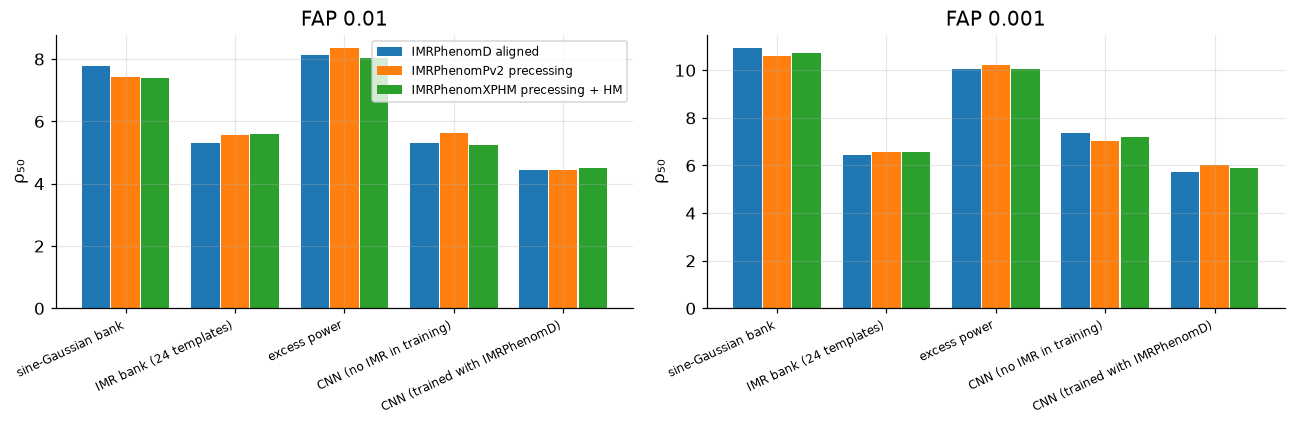

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4)); dets = list(VAL)
for a, far in zip(ax, (1e-2, 1e-3)):
    T = R[R.FAP == far].pivot_table(index="detector", columns="family", values="rho50").loc[dets]
    for j, fam in enumerate(T.columns): a.bar(np.arange(len(dets)) + 0.27 * (j - 1), T[fam], width=0.26, label=fam)
    a.set_xticks(range(len(dets))); a.set_xticklabels(dets, rotation=25, ha="right", fontsize=8); a.set_ylabel("ρ₅₀"); a.set_title(f"FAP {far:g}")
ax[0].legend(fontsize=8); fig.tight_layout(); g.savefig(fig, "fig29_precession_hm"); plt.show()
g.save_json(dict(rho50=R.to_dict("records"), fitting_factor=FFt.reset_index().to_dict("records")), "29_summary.json")

## Output and next step

`results/29_summary.json`, `figures/fig29_precession_hm`, libraries `cache/lib_*.npz`. Next: seed study and paired tests (extension 2), then Bayesian evidence and coherent analyses.